# 10 · Cancelled sessions: genuine ones, and cancelling to dodge a rescan (v1.2)

A shopper can cancel SmartShop part-way through and pay at a staffed till. Usually that is
ordinary: a flat battery, an app crash, a change of mind. But it can also be a way round the
policy: told "you've been selected for a rescan", a shopper cancels and pays at a till for what
they put on the belt, keeping whatever they hid. If cancelling carries no consequence:

- any rescan policy can be dodged, and the better it picks out thieves, the more of the people it
  asks have something to hide;
- loss measured from the rescans that were completed misses exactly the sessions most likely to
  hold it.

Two sets of rules are compared, for today's random rescans and the v1.1 policy, at the same
colleague time:

| | Today's rules (open) | Closed rules (v1.2) |
|---|---|---|
| Cancel part-way | Pay at a till; no exit decision | Treated as an exit: the same decision |
| Selected, then cancel | Pay at a till; the rescan is skipped | The session is locked; a colleague completes the rescan |
| Crash or flat battery logged *by the app* | As above | Random floor (2%) only, so a genuine failure is never singled out |
| Would-be dodgers under the lock | — | Some abandon the trolley and leave (their hidden items are lost) |

At a staffed till everything on the belt is scanned, so honest mistakes are paid for; only items
deliberately hidden are lost. Shoppers who steal respond to the rescan chance they *effectively*
face, so an open loophole also invites more theft. No published figure exists for how often people
cancel or dodge, so the base values are stated assumptions (3% of sessions cancelled genuinely,
40% of them logged by the app; 40–60% of selected shoppers with hidden items dodge; 15% walk
away under the lock), and six other worlds vary them.

Produced by `python -m smartshop.reporting.cancellations`; this notebook reads its outputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../models/cancellations.csv')
meas = pd.read_csv('../models/cancellations_measurement.csv').set_index('rules')
base = t[t.world.isin(['No cancellations (reference)', 'Cancellations as assumed'])]
cols = ['world', 'arm', 'rules', 'loss_remaining', 'loss vs today (open rules)',
        'hidden_loss_in_dodged_rescans', 'rescans_dodged_or_refused', 'honest_stops',
        'adaptive_stealing', 'colleague_hours']
base[cols].round(3)

,world,arm,rules,loss_remaining,loss vs today (open rules),hidden_loss_in_dodged_rescans,rescans_dodged_or_refused,honest_stops,adaptive_stealing,colleague_hours
0,No cancellations (reference),Today,-,41639.170,NaN,NaN,NaN,5428.200,0.663,113.444
1,No cancellations (reference),Policy v1.1,-,33363.607,NaN,NaN,NaN,1911.684,0.708,113.444
2,Cancellations as assumed,Today,open,42781.717,0.000,2152.528,254.408,5238.233,0.780,118.786
3,Cancellations as assumed,Policy v1.1,open,38065.511,-0.110,4396.440,222.584,1909.544,0.759,118.786
4,Cancellations as assumed,Today,closed,41660.589,-0.026,308.460,35.501,5135.022,0.673,118.786
5,Cancellations as assumed,Policy v1.1,closed,34239.396,-0.200,576.843,27.428,1826.152,0.721,118.786


## 1. What the loophole costs, and what closing it recovers

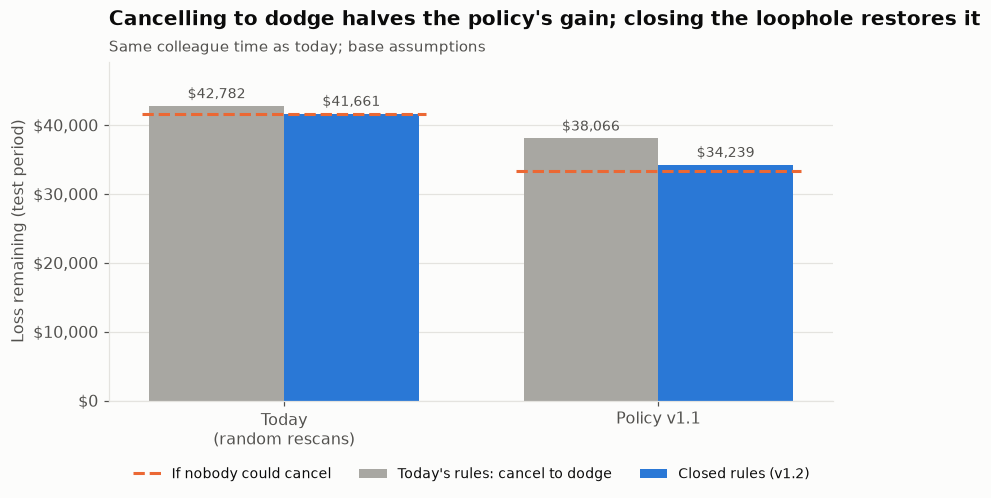

In [2]:
b = t[t.world == 'Cancellations as assumed'].set_index(['arm', 'rules'])
ref = t[t.world == 'No cancellations (reference)'].set_index('arm')
fig, ax = plt.subplots(figsize=(8.5, 4))
labels = ['Today\n(random rescans)', 'Policy v1.1']
x = np.arange(2)
open_ = [b.loc[('Today', 'open'), 'loss_remaining'], b.loc[('Policy v1.1', 'open'), 'loss_remaining']]
closed = [b.loc[('Today', 'closed'), 'loss_remaining'], b.loc[('Policy v1.1', 'closed'), 'loss_remaining']]
b1 = ax.bar(x - 0.18, open_, 0.36, color=GREY, label="Today's rules: cancel to dodge")
b2 = ax.bar(x + 0.18, closed, 0.36, color=BLUE, label='Closed rules (v1.2)')
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f'${v:,.0f}' for v in bars.datavalues], padding=3, color=TEXT_2, fontsize=9)
for xi, arm in zip(x, ['Today', 'Policy v1.1']):
    ax.hlines(ref.loc[arm, 'loss_remaining'], xi - 0.38, xi + 0.38, color=ORANGE, lw=2, ls='--',
              zorder=3, label='If nobody could cancel' if xi == 0 else None)
ax.set_xticks(x, labels)
ax.set_ylabel('Loss remaining (test period)')
ax.yaxis.set_major_formatter(money())
ax.set_ylim(0, max(open_) * 1.15)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
ax.grid(axis='x', visible=False)
ax.set_title('Cancelling to dodge halves the policy\'s gain; closing the loophole restores it')
subtitle(ax, 'Same colleague time as today; base assumptions')
save(fig, '24_cancellation_loophole')
fig

**Reading it.**

- Under today's rules, v1.1 still beats today's random rescans, but its gain shrinks from about
  20% to about 11%. **The loophole hurts the risk-based policy more than it hurts random
  rescans**: the better a policy picks out thieves, the more of the shoppers it asks have
  something to hide, and they are the ones who dodge. Hidden loss kept by dodgers is about twice
  as large under v1.1 as under today's random rescans.
- Closing the loophole brings v1.1 back to about 20% less loss than today, close to the
  no-cancellation reference; what remains is shoppers who abandon the trolley and leave.
- An open loophole also invites more theft: adaptive shoppers steal more often when a rescan can be
  dodged.

## 2. Genuine cancellers

In [3]:
g = t[t.world == 'Cancellations as assumed'].copy()
n_sessions = 47314  # test-period sessions
g['genuine cancellers asked for a rescan'] = g.genuine_cancellers_stopped / g.genuine_cancellations
g['all honest shoppers asked for a rescan'] = g.honest_stops / (n_sessions - g.sessions_with_theft)
g[['arm', 'rules', 'genuine_cancellations', 'genuine cancellers asked for a rescan',
   'all honest shoppers asked for a rescan']].round(3)

,arm,rules,genuine_cancellations,genuine cancellers asked for a rescan,all honest shoppers asked for a rescan
2,Today,open,1350.06,0.000,0.116
3,Policy v1.1,open,1350.03,0.000,0.042
4,Today,closed,1356.12,0.077,0.114
5,Policy v1.1,closed,1352.43,0.032,0.041


Under closed rules a genuine canceller is asked for a rescan **no more often than any honest
shopper who finishes**: a cancellation the app logs as a crash or flat battery gets only the random
floor, and the rest get the same decision as at the exit. Nobody is flagged *for* cancelling, and
mid-shop cancellations are never used as a risk signal. The crash flag must come from the app's own
logs, never from what the shopper says, or it becomes the new loophole.

## 3. Measuring loss when rescans can be dodged

In [4]:
meas.round(3)

,bias,error,rescans requested,dodged or refused
rules,,,,
open,-0.378,0.063,2231.0,225.533
closed,-0.064,0.097,2083.1,28.567


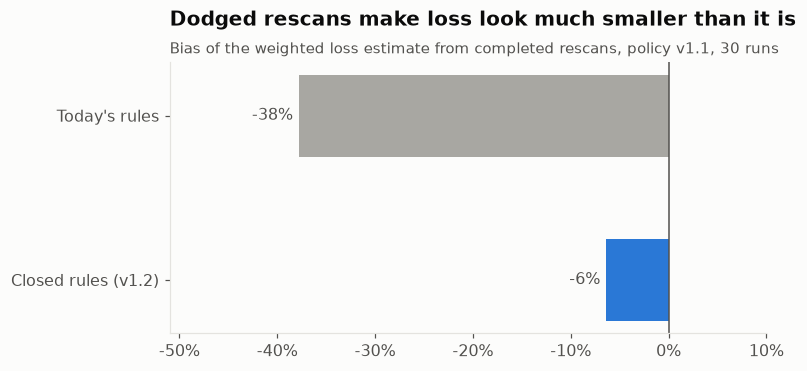

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [meas.loc['open', 'bias'], meas.loc['closed', 'bias']]
bars = ax.barh(["Today's rules", 'Closed rules (v1.2)'], vals, color=[GREY, BLUE], height=0.5)
ax.bar_label(bars, labels=[f'{v:+.0%}' for v in vals], padding=4, color=TEXT_2)
ax.axvline(0, color=TEXT_2, lw=1)
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(min(vals) * 1.35, 0.1)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_title('Dodged rescans make loss look much smaller than it is')
subtitle(ax, 'Bias of the weighted loss estimate from completed rescans, policy v1.1, 30 runs')
save(fig, '25_cancellation_measurement')
fig

The inverse-probability estimate from week 8 assumes every requested rescan happens. When
selected shoppers can cancel, the missing rescans are not random: they are the shoppers with
something hidden. Under today's rules the estimate misses over a third of the loss; with the lock
the remaining bias comes only from those who walk away, and it is visible: every walk-away after a
rescan request is logged, so the store can report it next to the loss estimate.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | If a selected shopper can cancel and pay at a till, v1.1's gain falls from about 20% to about 11% less loss than today | The loophole matters more than any modelling choice since week 8 |
| 2 | It hurts the risk-based policy more than random rescans: the better the policy targets, the more of those it asks have something to hide | Close the loophole before rolling out targeting |
| 3 | Closed rules (lock once selected; a cancellation is an exit; app-logged crashes get the floor) restore about 20% less loss, and it holds in all seven worlds tested | **v1.2 rules** |
| 4 | Genuine cancellers are asked for a rescan no more often than other honest shoppers; nobody is flagged for cancelling | Fair to people with a flat battery |
| 5 | Dodged rescans bias the loss estimate by about −38%; with the lock the bias falls to about −6%, from walk-aways the store can count | Report walk-aways next to the weighted loss estimate |